# Create a DEG list of the  healthy vs primary tumours in the data from NR Atlas
## Looking at all the DCs here first

Performing DEG analysis (limma, R) on all cancer data from the NR_atlas all DC data. Using code from NR's 2025-01-13-Pseudo_Cancer_DEGS.ipynb

Date: 13.04.2026

In [2]:
### install packages required

library(Seurat)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [3]:
library(sceasy)
library(reticulate)
use_condaenv('R_env')

Loading required package: reticulate



In [4]:
install.packages("edgeR")

Warning message:
“package ‘edgeR’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [5]:
library(limma)
library(edgeR)
library(dplyr)
library(ggplot2)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## Convert anndata object to seurat object

In [6]:
#Set working directory
getwd()
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis")

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code"

In [7]:
data <- '/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad' #this dataset has all the cancer atlas, DC data and primary and metastatic info

In [8]:
head(data)

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad"

In [9]:
sceasy::convertFormat(data, from="anndata", to="seurat", outFile='/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

X -> counts



An object of class Seurat 
1746 features across 29887 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

# Read in converted data

In [10]:
data <- readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

Explore the data structure

In [11]:
head(data)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15629172,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.18922702,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.13527090,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.36721915,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.32900991,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.14672113,0.08149318,0.174721746,-0.17654256
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117,1505,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15998438,-0.05433711,-0.048045593,0.74123969
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875,1515,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15336146,-0.02565772,0.004267385,0.53398699
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887,1846,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.05677931,0.42842232,0.365930736,-0.08318085


In [12]:
class(data)

[1] "Seurat"
attr(,"package")
[1] "SeuratObject"

In [13]:
#Basic Structure
slotNames(data)

[1] "assays"       "meta.data"    "active.assay" "active.ident" "graphs"      
 [6] "neighbors"    "reductions"   "images"       "project.name" "misc"        
[11] "version"      "commands"     "tools"

In [14]:
#Metadata and cells
colnames(data)           # cell IDs
head(colnames(data))
head(data@meta.data)

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1"                                                  
    [2] "GSE215120_AM1_ACACTGATCCACTGGG-1"                                                  
    [3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1"                                                  
    [4] "GSE215120_AM1_ACCAGTAAGACTGGGT-1"                                                  
    [5] "GSE215120_AM1_ACGTCAACAAGGACTG-1"                                                  
    [6] "GSE215120_AM1_ACGTCAATCCGCATCT-1"                                                  
    [7] "GSE215120_AM1_ACTGAGTCAGGCTGAA-1"                                                  
    [8] "GSE215120_AM1_ACTGTCCGTCTCTTAT-1"                                                  
    [9] "GSE215120_AM1_ACTTGTTTCTGAAAGA-1"                                                  
   [10] "GSE215120_AM1_AGAGCTTGTACAGTTC-1"                                                  
   [11] "GSE215120_AM1_AGGGATGGTTTGTGTG-1"                                                  
   [12] "GSE215120_AM1_AGGTCATAGTACGCGA-1"                                                  
   [13] "GSE215120_AM1_AGGTCCGCATTCTTAC-1"                                                  
   [14] "GSE215120_AM1_ATAACGCGTAGCGCTC-1"                                                  
   [15] "GSE215120_AM1_ATAGACCCATTACCTT-1"                                                  
   [16] "GSE215120_AM1_ATCCACCCAGACGCTC-1"                                                  
   [17] "GSE215120_AM1_ATTGGTGAGTCTCGGC-1"                                                  
   [18] "GSE215120_AM1_CACTCCACACTAGTAC-1"                                                  
   [19] "GSE215120_AM1_CAGAGAGTCTTCATGT-1"                                                  
   [20] "GSE215120_AM1_CAGCATAGTGCGGTAA-1"                                                  
   [21] "GSE215120_AM1_CAGCATATCTGCCAGG-1"                                                  
   [22] "GSE215120_AM1_CAGCGACTCTCAACTT-1"                                                  
   [23] "GSE215120_AM1_CATGCCTGTTGGTTTG-1"                                                  
   [24] "GSE215120_AM1_CCATGTCCACCGCTAG-1"                                                  
   [25] "GSE215120_AM1_CCCTCCTGTCCAGTGC-1"                                                  
   [26] "GSE215120_AM1_CCGGGATTCAACACAC-1"                                                  
   [27] "GSE215120_AM1_CGAGCCATCCGAATGT-1"                                                  
   [28] "GSE215120_AM1_CGTCAGGAGGAGTACC-1"                                                  
   [29] "GSE215120_AM1_CGTGTAAGTTCGCTAA-1"                                                  
   [30] "GSE215120_AM1_CTAGTGAGTAGCACGA-1"                                                  
   [31] "GSE215120_AM1_CTAGTGATCACCCGAG-1"                                                  
   [32] "GSE215120_AM1_CTGCCTACAGCTGTTA-1"                                                  
   [33] "GSE215120_AM1_CTGCCTAGTTAAGTAG-1"                                                  
   [34] "GSE215120_AM1_CTGCTGTGTCGTCTTC-1"                                                  
   [35] "GSE215120_AM1_CTGTGCTAGTCGTACT-1"                                                  
   [36] "GSE215120_AM1_GACGGCTCACAAGTAA-1"                                                  
   [37] "GSE215120_AM1_GCAGTTATCATGTCCC-1"                                                  
   [38] "GSE215120_AM1_GCGAGAACACATAACC-1"                                                  
   [39] "GSE215120_AM1_GCGCAACTCGTAGGTT-1"                                                  
   [40] "GSE215120_AM1_GCGCAGTGTAACGACG-1"                                                  
   [41] "GSE215120_AM1_GCGCCAAAGAGAACAG-1"                                                  
   [42] "GSE215120_AM1_GCGCCAACAAGTAATG-1"                                                  
   [43] "GSE215120_AM1_GCGGGTTAGACTAGAT-1"                                                  
   [4

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1" "GSE215120_AM1_ACACTGATCCACTGGG-1"
[3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1" "GSE215120_AM1_ACCAGTAAGACTGGGT-1"
[5] "GSE215120_AM1_ACGTCAACAAGGACTG-1" "GSE215120_AM1_ACGTCAATCCGCATCT-1"

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1562917,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1892270,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1352709,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3672192,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3290099,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1467211,0.08149318,0.174721746,-0.17654256


In [15]:
#Check cancer type in object
unique(data@meta.data$cancer_type)

[1] Acral Melanoma        Cutaneous Melanoma    TNBC                 
 [4] HNSCC                 LUAD                  Healthy              
 [7] LUSC                  HER2 Breast Cancer    ER Breast Cancer     
[10] melanoma brain mets   HGSOC                 DCIS                 
[13] IDC                   ER breast cancer      BRCA1 TNBC           
[16] ER breast cancer mets HER2 breast cancer    PDAC                 
[19] CRC                   CRC - Healthy         breast cancer        
[22] Glioblastoma          Metastatic Melanoma   GAC liver mets       
[25] GAC ovarian mets      GAC primary           PDAC Liver mets      
[28] PDAC Lung mets        PDAC primary          CRC mets             
[31] HCC                   PC                    GBM                  
[34] iCCA                  healthy               NSCLC                
[37] NPC                   Diffuse-type GC Sup   Diffuse-type GC Deep 
39 Levels: Acral Melanoma BRCA1 TNBC CRC CRC - Healthy ... melanoma brain mets

In [16]:
#Check sample types (primary or met)
unique(data@meta.data$sample_type_major)
unique(data@meta.data$sample_type_major2)

[1] primary tumour    metastatic tumour local recurrence  healthy          
[5] ascites          
5 Levels: ascites healthy local recurrence ... primary tumour

[1] primary tumour    metastatic tumour healthy           ascites          
Levels: ascites healthy metastatic tumour primary tumour

In [17]:
table(data@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
             3513              3364              5674             17336 

In [18]:
#Assays and features
Assays(data)             # list assays
DefaultAssay(data)
rownames(data)           # gene names

[1] "RNA"

[1] "RNA"

[1] "KLHL17"     "HES4"       "ISG15"      "TNFRSF18"   "TNFRSF4"   
   [6] "MORN1"      "ACOT7"      "ERRFI1"     "SLC2A5"     "GPR157"    
  [11] "FBXO2"      "AGTRAP"     "PDPN"       "PRDM2"      "EPHA2"     
  [16] "PADI2"      "NBL1"       "HSPG2"      "C1QA"       "C1QC"      
  [21] "C1QB"       "LUZP1"      "TCEA3"      "ID3"        "FUCA1"     
  [26] "STPG1"      "RUNX3"      "LDLRAP1"    "STMN1"      "SFN"       
  [31] "SLC9A1"     "IFI6"       "SMPDL3B"    "RAB42"      "SDC3"      
  [36] "FABP3"      "SERINC2"    "LCK"        "MARCKSL1"   "FAM229A"   
  [41] "KIAA1522"   "ZC3H12A"    "POU3F1"     "CDC20"      "PTPRF"     
  [46] "MKNK1"      "PDZK1IP1"   "DHCR24"     "DAB1"       "TACSTD2"   
  [51] "JUN"        "NFIA"       "EFCAB7"     "ROR1"       "PDE4B"     
  [56] "GADD45A"    "WLS"        "CTH"        "NEGR1"      "ST6GALNAC3"
  [61] "AK5"        "DNAJB4"     "IFI44L"     "MCOLN2"     "ODF2L"     
  [66] "GBP1"       "GBP2"       "GBP4"       "GBP5"       "CDC7"      
  [71] "CNN3"       "DPYD"       "VCAM1"      "PRMT6"      "KIAA1324"  
  [76] "GSTM3"      "CSF1"       "KCNA3"      "DENND2D"    "MAGI3"     
  [81] "OLFML3"     "BCAS2"      "CD2"        "NBPF15"     "TXNIP"     
  [86] "FMO5"       "BCL9"       "PDE4DIP"    "HIST2H3D"   "HIST2H2AB" 
  [91] "C1orf54"    "ECM1"       "CTSK"       "C1orf56"    "SELENBP1"  
  [96] "CGN"        "TDRKH"      "TCHH"       "S100A9"     "S100A12"   
 [101] "S100A8"     "S100A7"     "S100A6"     "S100A4"     "S100A2"    
 [106] "S100A16"    "S100A14"    "S100A13"    "S100A1"     "RAB13"     
 [111] "ATP8B2"     "EFNA1"      "MUC1"       "RAB25"      "LMNA"      
 [116] "IQGAP3"     "NES"        "CRABP2"     "SH2D2A"     "ETV3"      
 [121] "CD1A"       "CD1C"       "CD1B"       "CD1E"       "PYHIN1"    
 [126] "FCER1A"     "SLAMF6"     "CD84"       "SLAMF1"     "SLAMF7"    
 [131] "LY9"        "USP21"      "FCGR2A"     "HSPA6"      "FCGR3A"    
 [136] "FCGR2B"     "NOS1AP"     "RGS5"       "PBX1"       "CD247"     
 [141] "CREG1"      "TNFSF18"    "TNFSF4"     "RABGAP1L"   "RASAL2"    
 [146] "ABL2"       "XPR1"       "IER5"       "GLUL"       "RGS16"     
 [151] "NPL"        "LAMC1"      "RGL1"       "IVNS1ABP"   "PTGS2"     
 [156] "CFH"        "ASPM"       "MIR181A1HG" "KIF14"      "TNNT2"     
 [161] "LAD1"       "ELF3"       "UBE2T"      "KDM5B"      "CHI3L1"    
 [166] "CHIT1"      "BTG2"       "ZC3H11A"    "ZBED6"      "PPP1R15B"  
 [171] "CDK18"      "SLC41A1"    "IL10"       "PIGR"       "PFKFB2"    
 [176] "YOD1"       "PLXNA2"     "LAMB3"      "G0S2"       "ATF3"      
 [181] "PTPN14"     "CENPF"      "DNAH14"     "ENAH"       "EPHX1"     
 [186] "TMEM63A"    "CDC42BPA"   "ARV1"       "FAM89A"     "TBCE"      
 [191] "GNG4"       "LYST"       "NID1"       "GPR137B"    "EDARADD"   
 [196] "ACTN2"      "KMO"        "AKT3"       "KIF26B"     "SMYD3"     
 [201] "NLRP3"      "ZNF692"     "PGBD2"      "SH3YL1"     "RSAD2"     
 [206] "LINC00299"  "RRM2"       "FAM49A"     "SDC1"       "RHOB"      
 [211] "ADCY3"      "KRTCAP3"    "CCDC121"    "TRMT61B"    "LBH"       
 [216] "CDC42EP3"   "CYP1B1"     "SLC8A1"     "EML4"       "ZFP36L2"   
 [221] "PRKCE"      "EPAS1"      "EPCAM"      "FBXO11"     "SPTBN1"    
 [226] "UGP2"       "PELI1"      "SPRED2"     "MXD1"       "PCYOX1"    
 [231] "CLEC4F"     "CD207"      "MCEE"       "SPR"        "EGR4"      
 [236] "MTHFD2"     "RTKN"       "RETSAT"     "SFTPB"      "GNLY"      
 [241] "ATOH8"      "ST3GAL5"    "CD8A"       "CD8B"       "EIF2AK3"   
 [246] "MAL"        "ANKRD36C"   "ADRA2B"     "ASTL"       "DUSP2"     
 [251] "NCAPH"      "FAHD2B"     "ANKRD36"    "AC159540.1" "ZAP70"     
 [256] "TMEM131"    "AFF3"       "PDCL3"      "TBC1D8"     "MAP4K4"    
 [261] "IL1R2"      "IL1R1"      "RANBP2"     "MERTK"      "SLC20A1"   
 [266] "CKAP2L"     "IL1A"       "IL1B"       "IL1RN"      "MARCO"     
 [271] "STEAP3"     "EPB41L5"    "NCKAP5"     "MGAT5"      "TMEM163"   
 [276] "ZRANB3"     "CXCR4"      "KYNU"    

In [19]:
# Check counts and normalized data
data[1:5, 1:5]           # small slice
GetAssayData(data, layer = "counts")[1:5, 1:5]
GetAssayData(data, layer = "data")[1:5, 1:5]

An object of class Seurat 
5 features across 5 samples within 1 assay 
Active assay: RNA (5 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

In [20]:
#Check DC types in object
unique(data@meta.data$NR_annotations_simple)

[1] cDC2   cDC1   mregDC
Levels: cDC1 cDC2 mregDC

In [21]:
table(data@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670  17166   6051 

Visualise the mreg DC UMAP in the Cancer dataset

In [22]:
#my_colors <- c("cDC1" = "#FF0000", "cDC2" = "#00FF00", "mregDC" = "")

my_cols <- c("mregDC" = "#8C564B", "cDC1" = "#E377C2", "cDC2" = "#AA40FC")

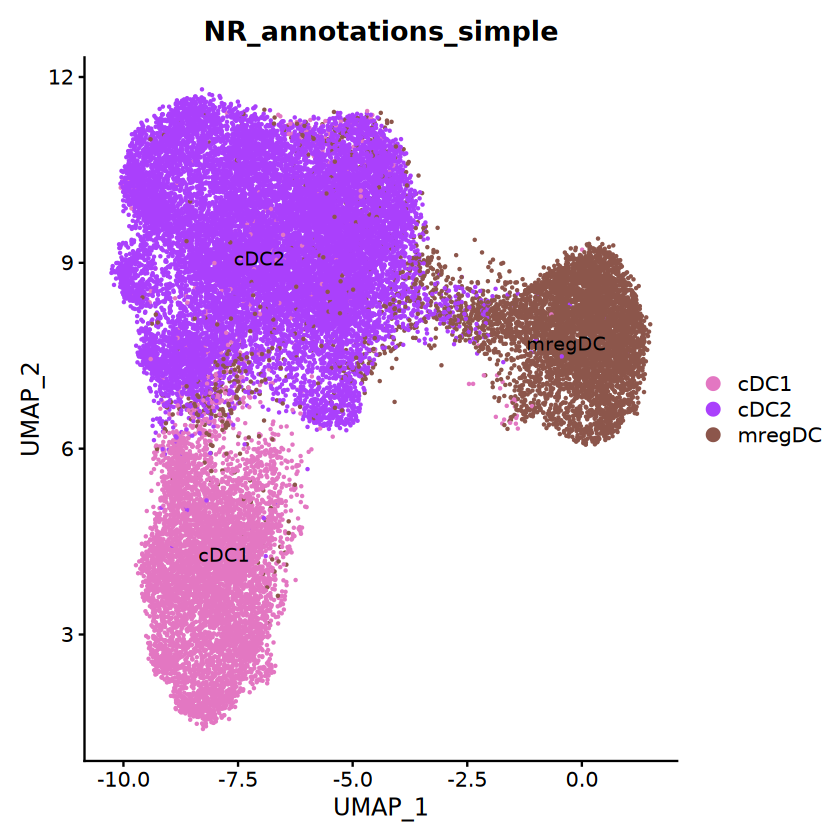

In [23]:
#FeaturePlot(oc.data, features = features)
DimPlot(data, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

# Create a DEG list (primary vs mets) of the mregDCs 

Use the code generated from Perplexity (23.3.26)

In [24]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "mregDC"

data_mregDC <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [25]:
data_mregDC

An object of class Seurat 
1746 features across 6051 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

In [26]:
#Confirm that our subsetted data only has our cells of interest
table(data_mregDC@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   6051 

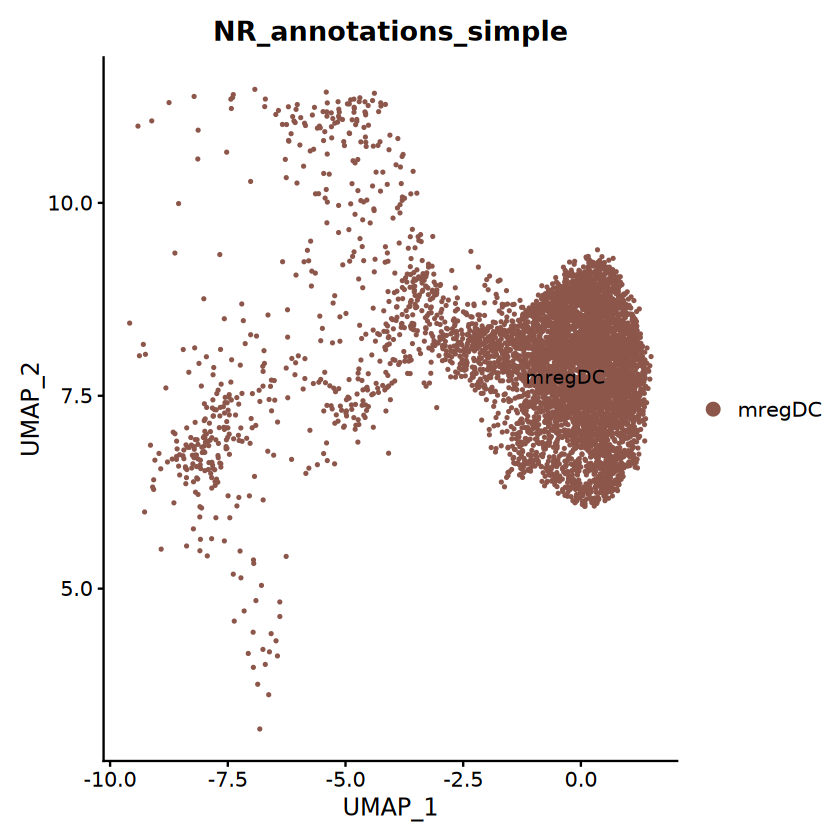

In [27]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_mregDC, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

In [28]:
# Set the cell identities to the "sample" metadata column
Idents(data_mregDC) <- data_mregDC@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC))


          ascites           healthy metastatic tumour    primary tumour 
              246               471              1103              4231 

In [29]:
#subset further to only have primary and metastatic data
data_mregDC_sub <- subset(data_mregDC,
subset = sample_type_major2 %in% c("healthy", "primary tumour"))


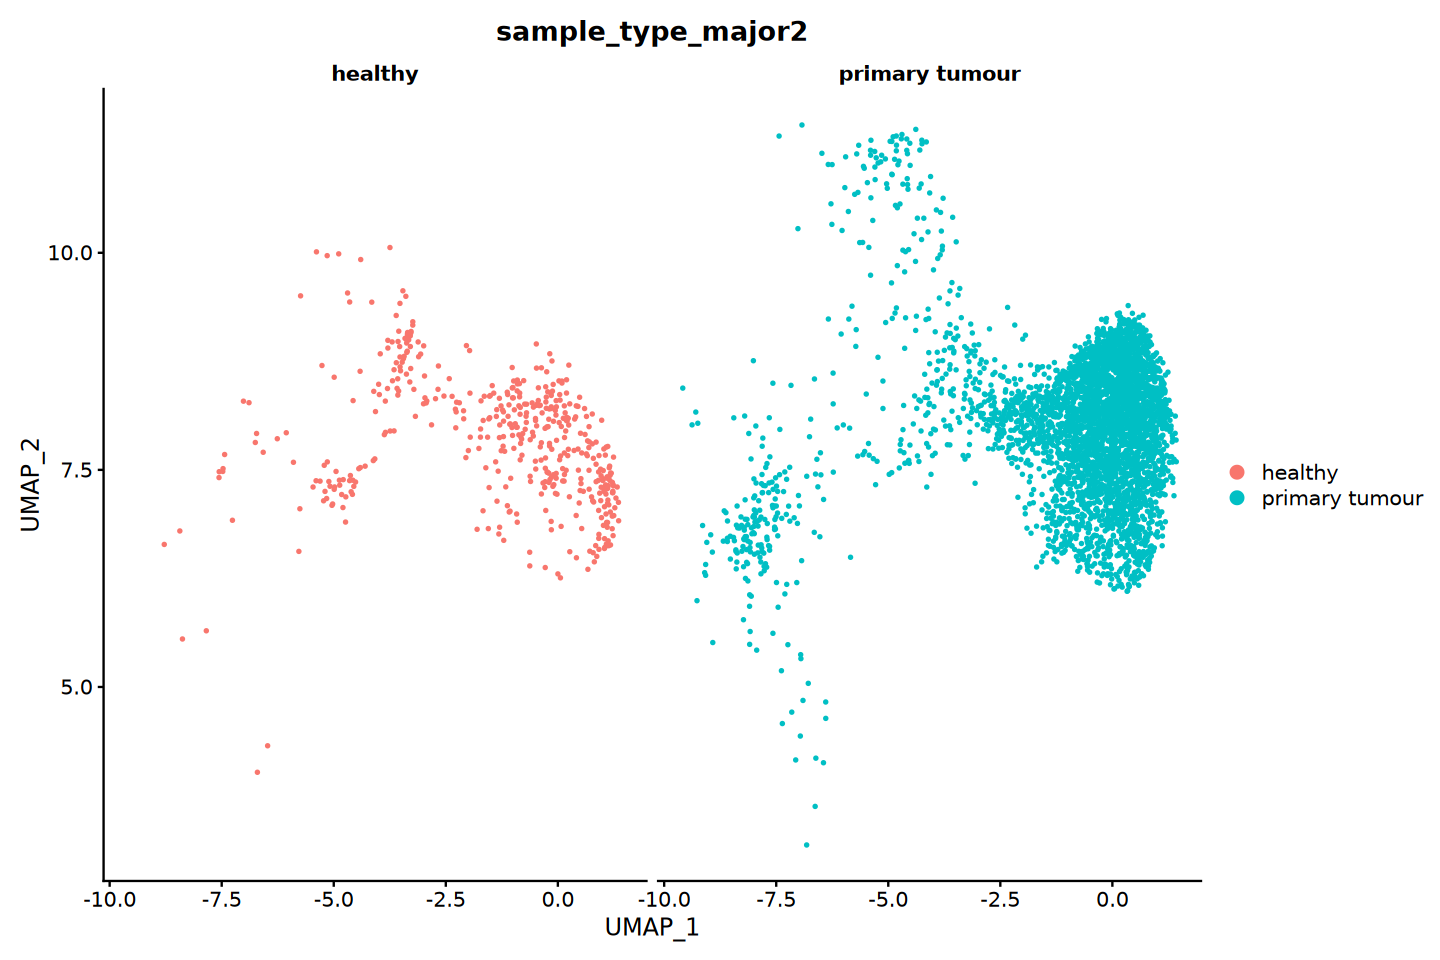

In [30]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_mregDC_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [31]:
table(data_mregDC_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   4702 

In [32]:
# Confirm the counts in the subsetted data
#Set the cell identities to the "sample" metadata column
Idents(data_mregDC_sub) <- data_mregDC_sub@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC_sub))


       healthy primary tumour 
           471           4231 

In [33]:
#Confirm that our subsetted data only has our states of interest
table(data_mregDC_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0               471                 0              4231 

Run Differential Expression between two states

In [34]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "primary tumour"

deg_res_mreg <- FindMarkers(
  object = data_mregDC_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777    
)

head(deg_res_mreg)

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,2.386962e-65,2.071472,0.777,0.408,4.167635e-62
DENND4A,1.806335e-37,3.219619,0.463,0.219,3.153861e-34
FSCN1,7.052657e-37,-1.309234,0.686,0.842,1.231394e-33
CD44,1.263121e-35,1.398874,0.705,0.449,2.205409e-32
PIK3R5,3.566151e-31,2.235364,0.389,0.166,6.226499e-28
CD1E,8.787372e-29,1.285721,0.403,0.217,1.534275e-25


deg_res will be a data frame with columns like:

* p_val

* avg_log2FC (or avg_logFC depending on Seurat version)

* pct.1 and pct.2

* p_val_adj

In [35]:
deg_sig_mreg <- subset(
  deg_res_mreg,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
XYLT1,3.435574e-27,5.671159,0.567,0.362,5.998512e-24
BACH2,8.621908e-08,5.235257,0.401,0.247,1.505385e-04
TRIO,3.743982e-19,5.022583,0.297,0.119,6.536993e-16
EXT1,1.953085e-06,5.018717,0.412,0.275,3.410086e-03
ENOX1,7.179723e-08,4.828795,0.234,0.115,1.253580e-04
GAB2,1.589193e-15,4.766934,0.416,0.245,2.774731e-12
PSD3,1.048455e-09,4.736646,0.359,0.211,1.830602e-06
NRG2,5.086964e-06,4.519457,0.163,0.036,8.881840e-03
L3MBTL4,2.681099e-13,4.517040,0.333,0.155,4.681199e-10


In [36]:
deg_sig_mreg

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,2.386962e-65,2.0714721,0.777,0.408,4.167635e-62
DENND4A,1.806335e-37,3.2196187,0.463,0.219,3.153861e-34
FSCN1,7.052657e-37,-1.3092340,0.686,0.842,1.231394e-33
CD44,1.263121e-35,1.3988745,0.705,0.449,2.205409e-32
PIK3R5,3.566151e-31,2.2353637,0.389,0.166,6.226499e-28
CD1E,8.787372e-29,1.2857210,0.403,0.217,1.534275e-25
SIK3,1.776302e-27,2.9309697,0.467,0.249,3.101423e-24
XYLT1,3.435574e-27,5.6711594,0.567,0.362,5.998512e-24
C1QB,4.575295e-27,1.0398261,0.304,0.160,7.988465e-24


Quick visualisation

In [37]:
top_genes_mreg <- rownames(head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_mreg


[1] "XYLT1"   "BACH2"   "TRIO"    "EXT1"    "ENOX1"   "GAB2"    "PSD3"   
 [8] "NRG2"    "L3MBTL4" "CLIP2"

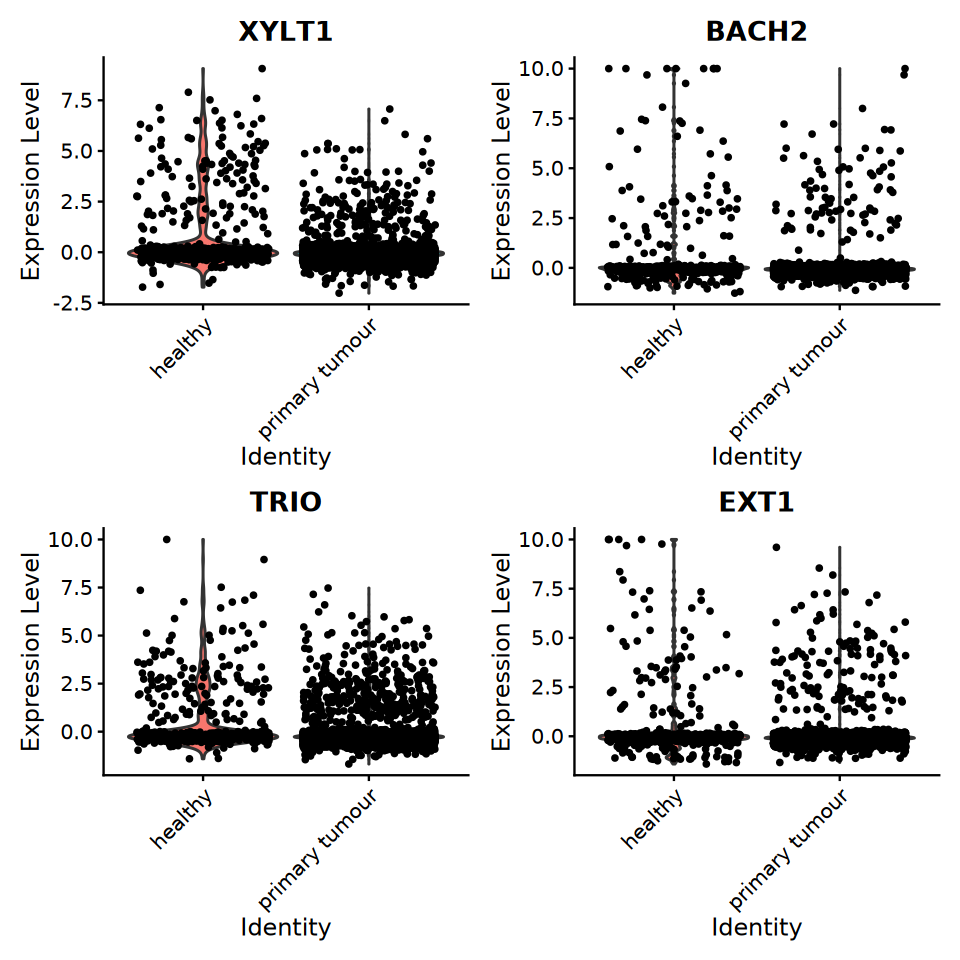

In [38]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_mregDC_sub, features = top_genes_mreg[1:4], group.by = "sample_type_major2", ncol = 2)

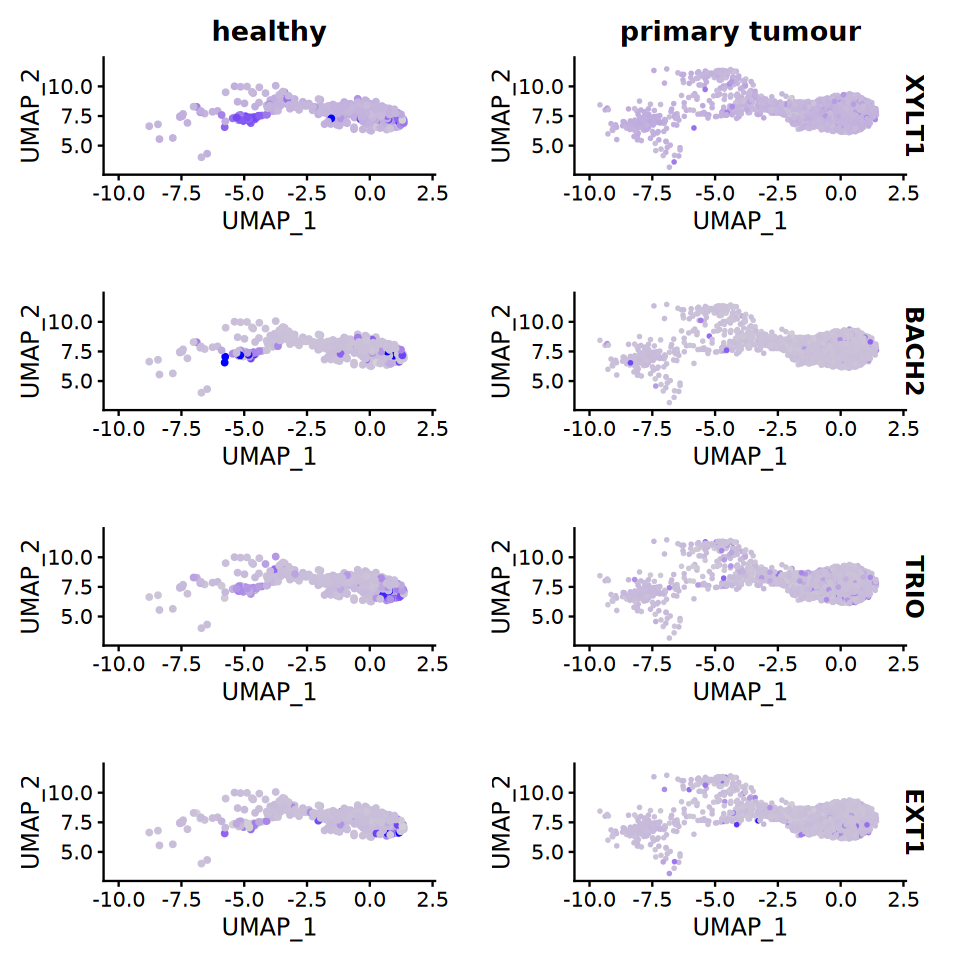

In [39]:
p <- FeaturePlot(data_mregDC_sub, features = top_genes_mreg[1:4], split.by = "sample_type_major2")
#ggsave("mregDEGfeatureplot.png", p, width = 8, height = 7, dpi = 300)
p

* XYLT1 ->  Xylosyltransferase 1 gene, found in humans on chromosome 16, encodes an enzyme essential for initiating the biosynthesis of glycosaminoglycan chains on proteoglycans, such as cartilage.
* BACH2 -> BTB and CNC homology 2 gene encodes a transcription factor critical for immune system function, particularly in B and T lymphocyte differentiation, maturation, and isotype switching.
* TRIO -> encodes a protein that acts as a Rho guanine nucleotide exchange factor (GEF), essential for regulating the actin cytoskeleton, neurite outgrowth, and synapse development in the brain.
* EXT1 -> Exostosin Glycosyltransferase is a protein-coding gene located on chromosome 8 that plays a critical role in producing the exostosin-1 enzyme.


# Create a DEG list (healthy vs primary) of the cDC2s

In [40]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC2"

data_cDC2 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [41]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC2@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0  17166      0 

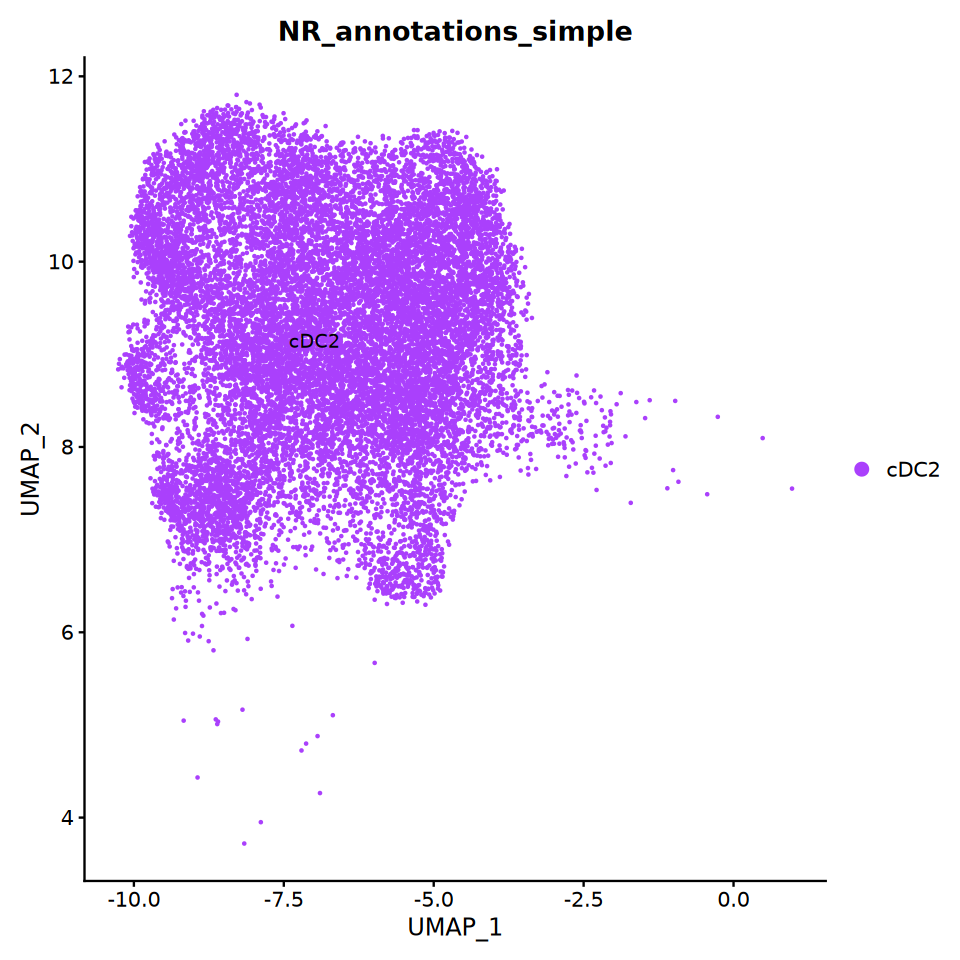

In [42]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC2, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set Identities for the sample column

In [43]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC2) <- data_cDC2@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC2))


          ascites           healthy metastatic tumour    primary tumour 
             2242              2188              3172              9564 

In [44]:
#subset further to only have primary and metastatic data
data_cDC2_sub <- subset(data_cDC2,
subset = sample_type_major2 %in% c("healthy", "primary tumour"))


In [45]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC2_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0              2188                 0              9564 

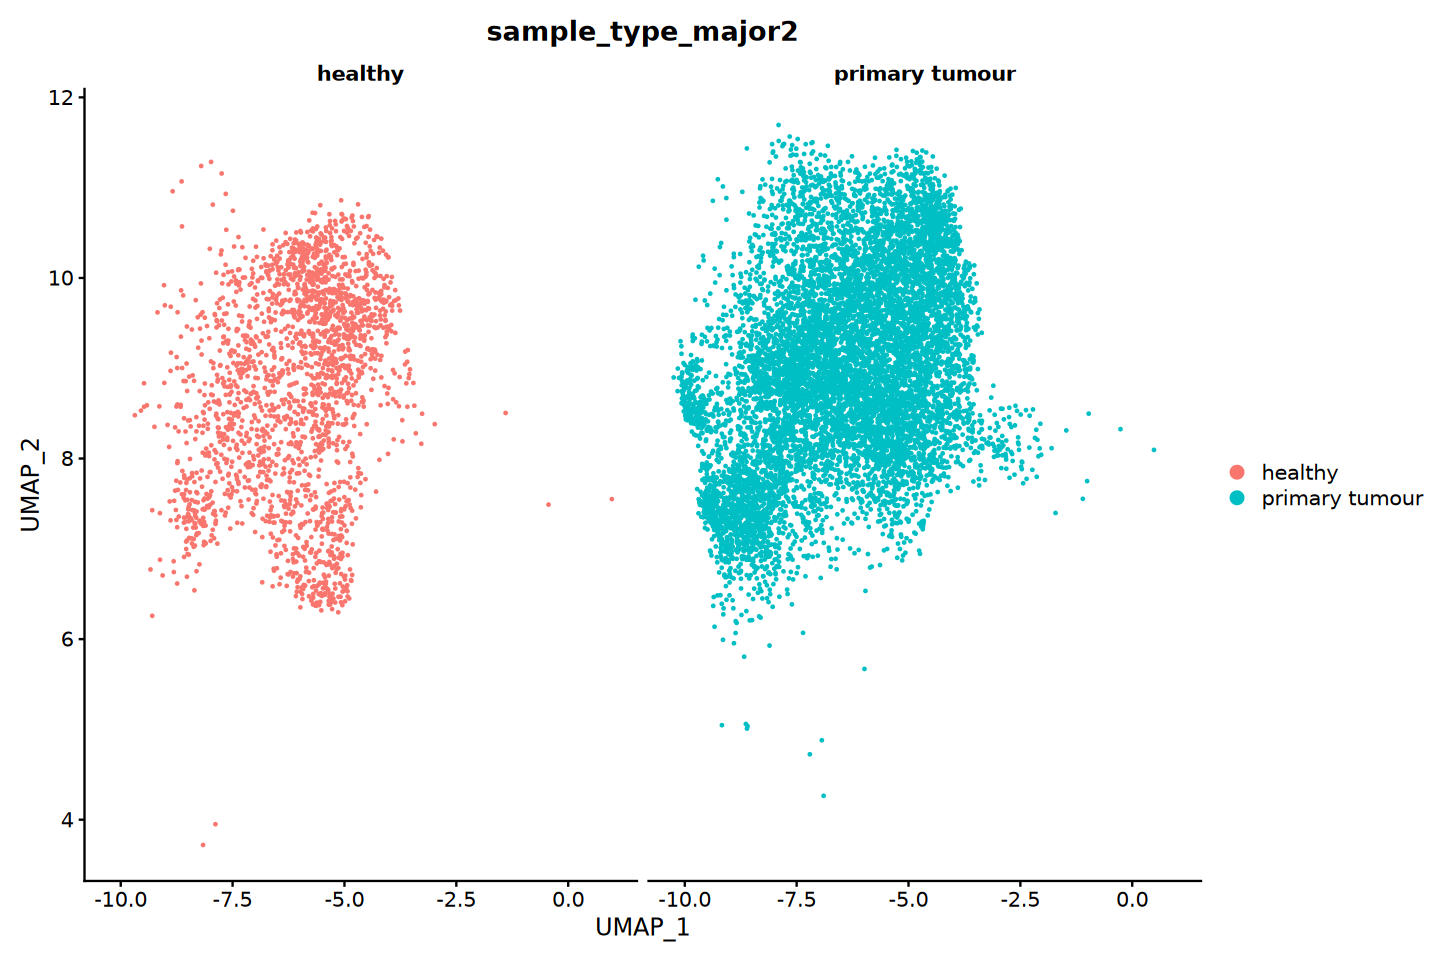

In [46]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC2_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [47]:
#confirm our subset counts
table(data_cDC2_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0  11752      0 

Run Differential Expression between two states

In [48]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "primary tumour"

deg_res_dc2 <- FindMarkers(
  object = data_cDC2_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc2)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,1.567235e-229,1.520536,0.840,0.531,2.736392e-226
IFITM3,1.478491e-106,-2.880824,0.393,0.606,2.581446e-103
IFITM2,3.086161e-65,-2.327153,0.371,0.543,5.388438e-62
SPP1,3.305750e-65,-6.664380,0.031,0.202,5.771839e-62
IFI6,4.218011e-58,-1.837905,0.235,0.385,7.364647e-55
LMNA,8.156201e-57,1.097379,0.626,0.467,1.424073e-53


In [49]:
deg_sig_dc2 <- subset(
  deg_res_dc2,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
XYLT1,5.952032e-51,6.380797,0.470,0.382,1.039225e-47
ZC3H12C,1.069671e-18,5.500118,0.367,0.318,1.867645e-15
BMP6,8.187197e-11,4.878532,0.418,0.375,1.429485e-07
UST,4.542487e-45,4.605633,0.440,0.359,7.931183e-42
CCSER1,7.144785e-38,4.461721,0.299,0.236,1.247480e-34
ST18,2.230703e-07,4.334315,0.245,0.246,3.894808e-04
ZHX2,2.159476e-34,4.305972,0.326,0.268,3.770446e-31
ZSWIM6,7.911780e-19,4.293204,0.312,0.279,1.381397e-15
IDO2,8.294395e-26,4.164300,0.122,0.052,1.448201e-22


Quick Visualisation

In [50]:
top_genes_dc2 <- rownames(head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc2

[1] "XYLT1"   "ZC3H12C" "BMP6"    "UST"     "CCSER1"  "ST18"    "ZHX2"   
 [8] "ZSWIM6"  "IDO2"    "RPS27L"

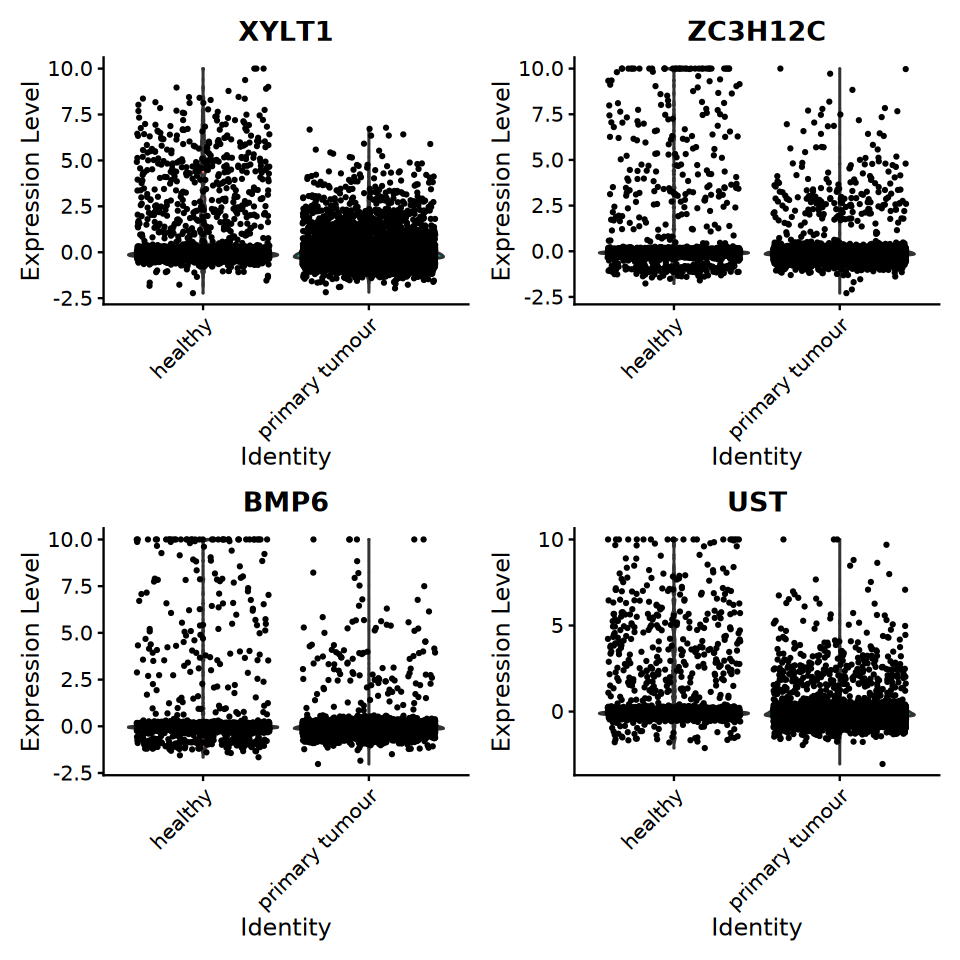

In [51]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_cDC2_sub, features = top_genes_dc2[1:4], group.by = "sample_type_major2", pt.size = 0.5, ncol = 2)

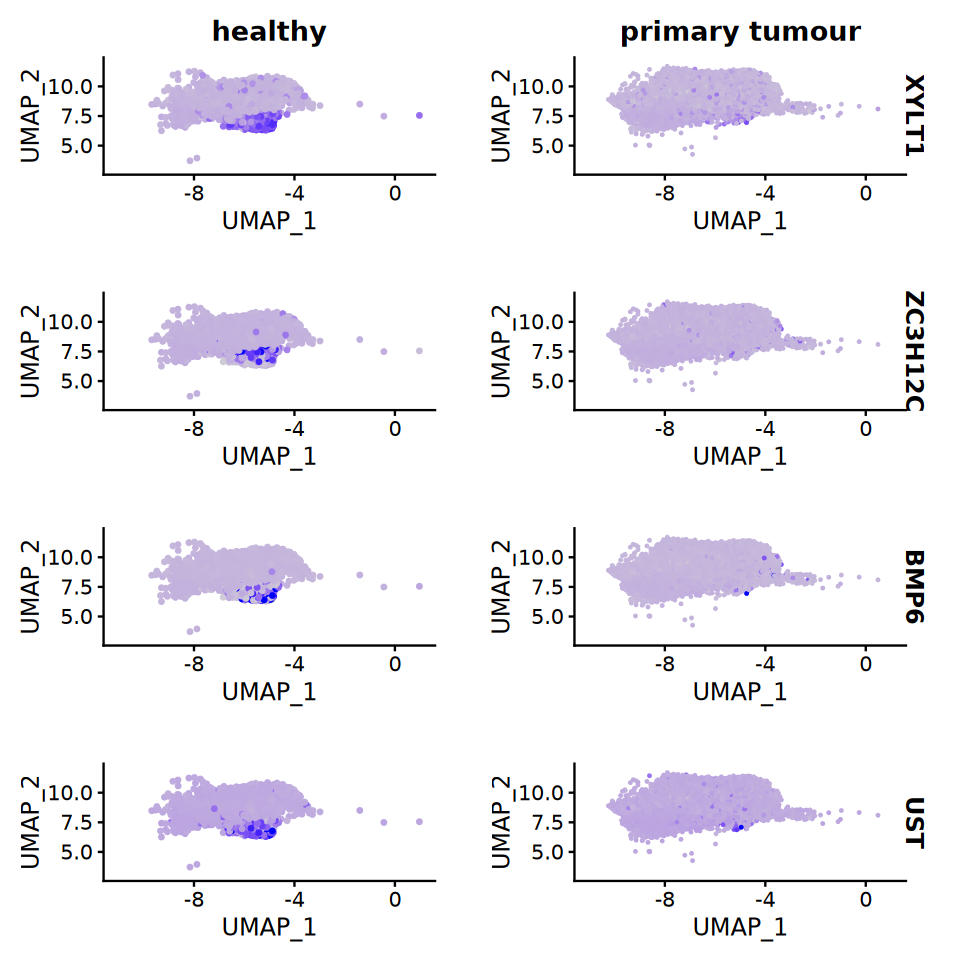

In [52]:
FeaturePlot(data_cDC2_sub, features = top_genes_dc2[1:4], split.by = "sample_type_major2")

* XYLT1 ->   Xylosyltransferase 1 gene, found in humans on chromosome 16, encodes an enzyme essential for initiating the biosynthesis of glycosaminoglycan chains on proteoglycans, such as cartilage.
* ZC3H12C -> Zinc Finger CCCH-Type Containing 12C  6 encodes a type I intermediate filament protein that provides structural integrity to epithelial cells, particularly in the skin, nails, and oral mucosa.
* BMP6 -> encodes a member of the TGF-B superfamily, acting as a critical signaling molecule for bone formation, iron homeostasis, and cellular differentiation.
* UST -> Uronyl 2-Sulfotransferase encodes an enzyme that transfers sulfate to the 2-position of uronyl residues, specifically iduronyl residues in dermatan sulfate and glucuronyl residues in chondroitin sulfate.

# Create a DEG list (primary vs mets) of the cDC1s

In [53]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC1"

data_cDC1 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [54]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC1@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670      0      0 

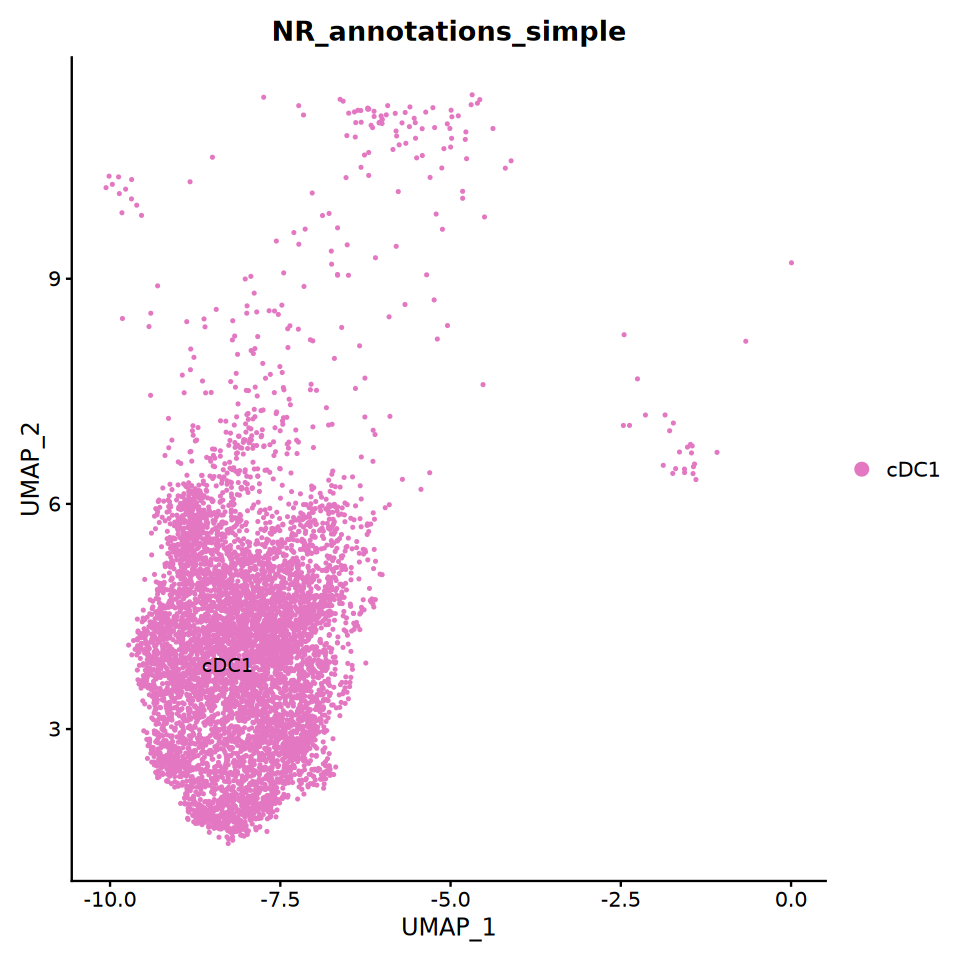

In [55]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC1, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set identities for the sample column

In [56]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC1) <- data_cDC1@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC1))


          ascites           healthy metastatic tumour    primary tumour 
             1025               705              1399              3541 

In [57]:
#subset further to only have primary and metastatic data
data_cDC1_sub <- subset(data_cDC1,
subset = sample_type_major2 %in% c("healthy", "primary tumour"))

In [58]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC1_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0               705                 0              3541 

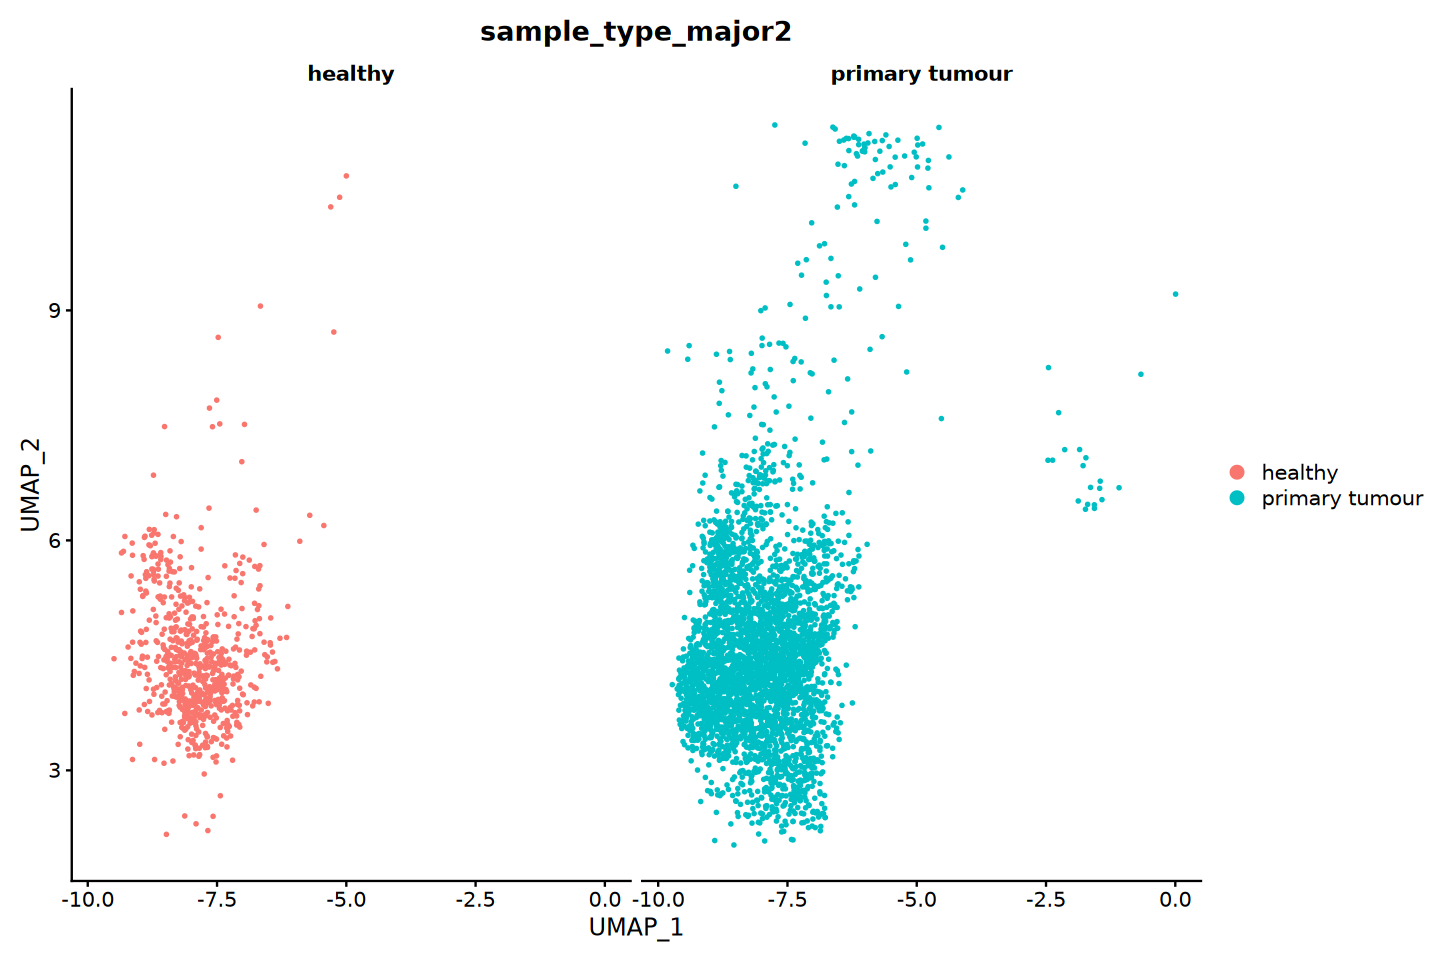

In [59]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC1_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [60]:
#confirm our cell counts
table(data_cDC1_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  4246      0      0 

Run Differential Expression between the states

In [61]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "primary tumour"

deg_res_dc1 <- FindMarkers(
  object = data_cDC1_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc1)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,1.235412e-129,2.1283541,0.845,0.479,2.157029e-126
SNX3,3.522085e-42,0.7875289,0.904,0.848,6.149560e-39
LMNA,6.134253e-37,1.2175048,0.742,0.582,1.071041e-33
TACSTD2,1.618833e-30,1.1104316,0.600,0.449,2.826483e-27
RGCC,3.169275e-25,0.8237392,0.810,0.715,5.533554e-22
ANXA1,6.142369e-25,2.5379033,0.538,0.314,1.072458e-21


In [51]:
deg_sig_dc1 <- subset(
  deg_res_dc1,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], n = 10)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
XYLT1,3.542356e-07,8.986986,0.356,0.336,6.184954e-04
DNAH17,1.863835e-06,7.110930,0.162,0.182,3.254257e-03
BMP6,4.648386e-06,5.804902,0.393,0.381,8.116082e-03
ZHX2,2.698922e-07,5.568477,0.281,0.277,4.712319e-04
UST,2.788116e-13,4.360210,0.404,0.357,4.868051e-10
PHLPP1,2.600116e-12,4.073815,0.338,0.300,4.539802e-09
PITPNC1,2.863315e-10,4.017701,0.284,0.279,4.999348e-07
EXT1,5.082696e-09,3.579734,0.326,0.303,8.874387e-06
SIPA1L1,4.226510e-07,3.543452,0.262,0.240,7.379486e-04


Quick Visualisation

In [52]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc1

[1] "XYLT1"   "DNAH17"  "BMP6"    "ZHX2"    "UST"     "PHLPP1"  "PITPNC1"
 [8] "EXT1"    "SIPA1L1" "CRIP2"

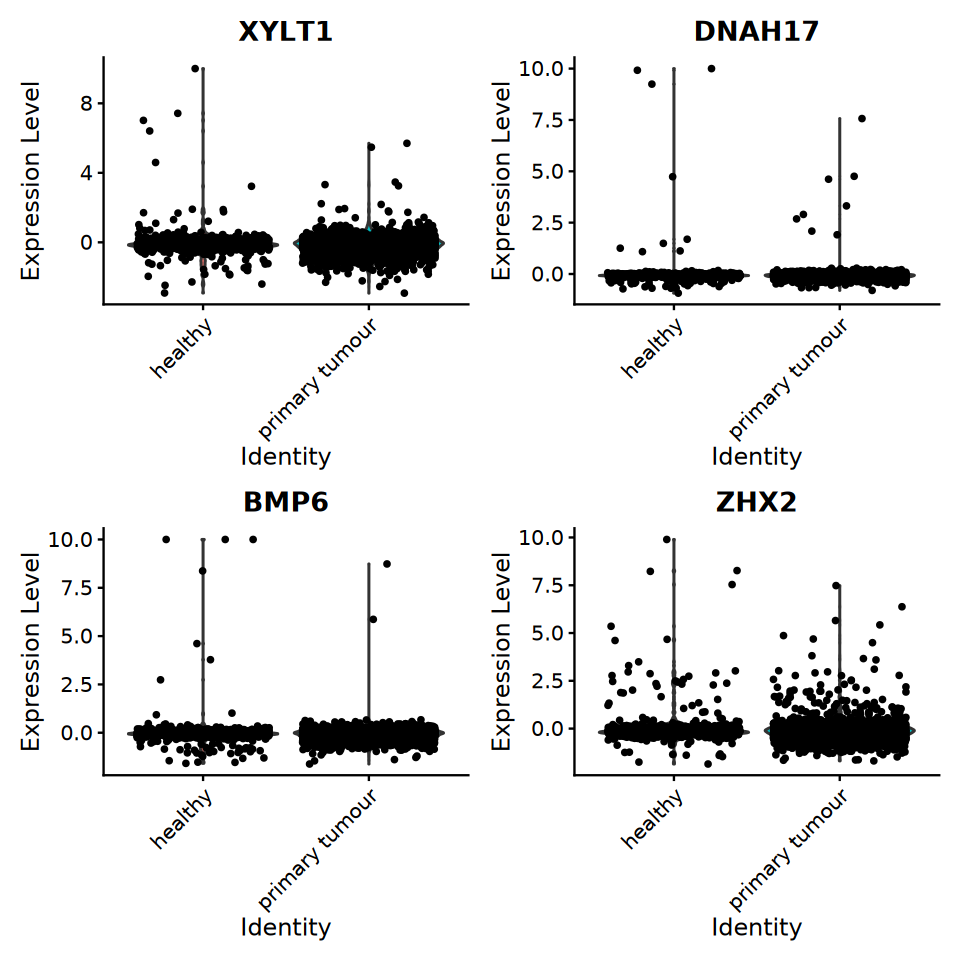

In [59]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_cDC1_sub, features = top_genes_dc1[1:4], group.by = "sample_type_major2", ncol = 2) #, pt.size = 0.05

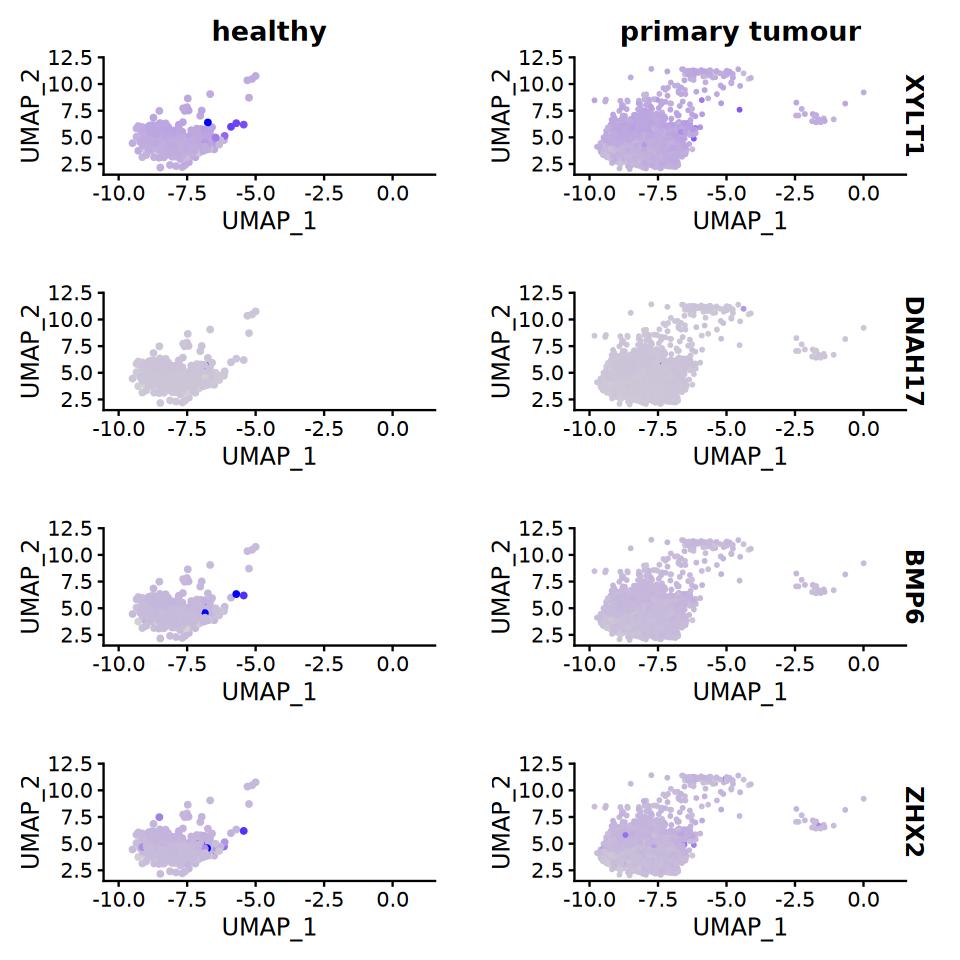

In [60]:
FeaturePlot(data_cDC1_sub, features = top_genes_dc1[1:4], split.by = "sample_type_major2")

* XYLT1 ->   Xylosyltransferase 1 gene, found in humans on chromosome 16, encodes an enzyme essential for initiating the biosynthesis of glycosaminoglycan chains on proteoglycans, such as cartilage.
* DNAH17 Dynein Axonemal Heavy Chain 17 encodes a protein crucial for forming the outer dynein arms (ODAs) in the sperm flagellum, acting as a microtubule motor.
* BMP6 -> encodes a member of the TGF-B superfamily, acting as a critical signaling molecule for bone formation, iron homeostasis, and cellular differentiation. 
* ZHX2 -> Zinc Fingers and Homeoboxes 2 encodes a nuclear transcription factor that often acts as a tumor suppressor, regulating gene expression in cancers like hepatocellular carcinoma


# Trying to make a Volcano Plot

In [ ]:
head(deg_res_mreg)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48
UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47
JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47
CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40
HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40


In [61]:
mreg_vp <- deg_res_mreg %>%
tibble::rownames_to_column("gene")%>%
arrange(p_val_adj, desc(avg_log2FC))

In [ ]:
head(mreg_vp, 10)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48
2,UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47
3,JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47
4,CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
5,SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40
6,HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40
7,FSCN1,2.278522e-36,0.822293,0.842,0.787,3.978300e-33
8,ANKRD28,7.817792e-35,2.196210,0.100,0.083,1.364986e-31
9,CST7,6.723106e-34,1.383251,0.645,0.456,1.173854e-30


Create Violin plot - mreg

In [65]:
mreg_vp <- deg_res_mreg%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

In [66]:
head(mreg_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,RPS17,2.386962e-65,2.071472,0.777,0.408,4.167635e-62,61.38011,TRUE
2,DENND4A,1.806335e-37,3.219619,0.463,0.219,3.153861e-34,33.50116,TRUE
3,FSCN1,7.052657e-37,-1.309234,0.686,0.842,1.231394e-33,32.90960,TRUE
4,CD44,1.263121e-35,1.398874,0.705,0.449,2.205409e-32,31.65651,TRUE
5,PIK3R5,3.566151e-31,2.235364,0.389,0.166,6.226499e-28,27.20576,TRUE
6,CD1E,8.787372e-29,1.285721,0.403,0.217,1.534275e-25,24.81410,TRUE


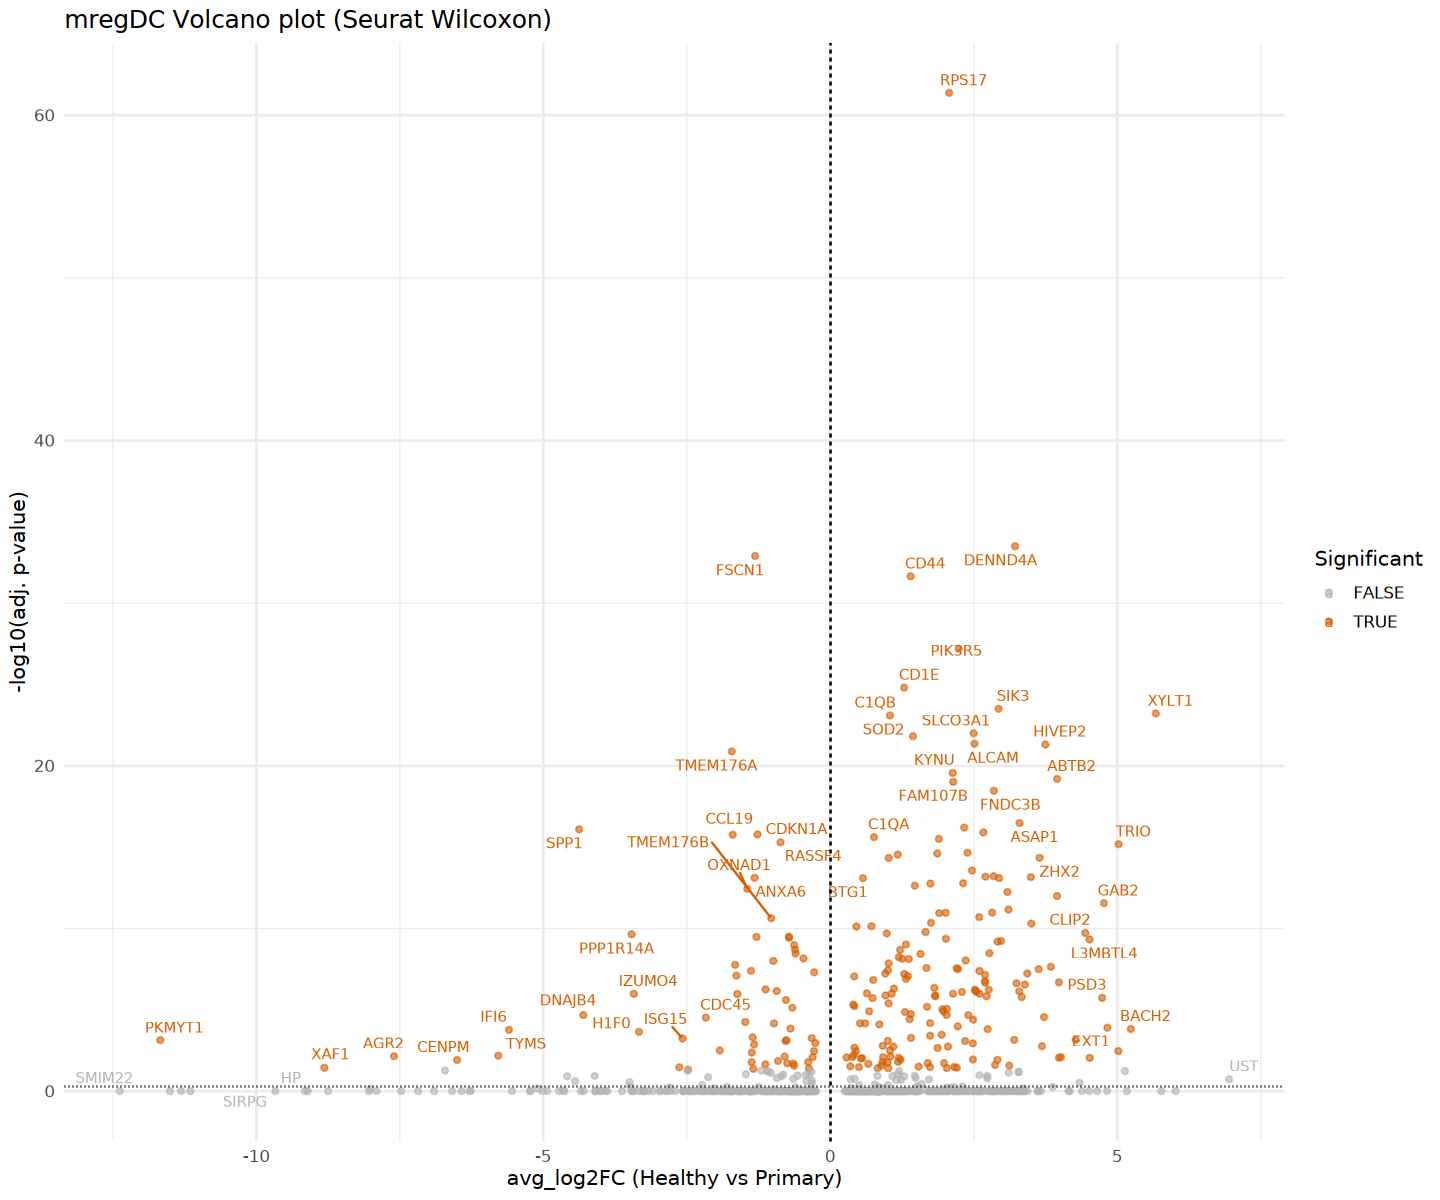

In [67]:

ggplot(mreg_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "mregDC Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Primary)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


Create Violin plot - cDC1

In [62]:
dc1_vp <- deg_res_dc1%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

head(dc1_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,RPS17,1.235412e-129,2.1283541,0.845,0.479,2.157029e-126,125.66614,TRUE
2,SNX3,3.522085e-42,0.7875289,0.904,0.848,6.149560e-39,38.21116,TRUE
3,LMNA,6.134253e-37,1.2175048,0.742,0.582,1.071041e-33,32.97019,TRUE
4,TACSTD2,1.618833e-30,1.1104316,0.600,0.449,2.826483e-27,26.54875,TRUE
5,RGCC,3.169275e-25,0.8237392,0.810,0.715,5.533554e-22,21.25700,TRUE
6,ANXA1,6.142369e-25,2.5379033,0.538,0.314,1.072458e-21,20.96962,TRUE


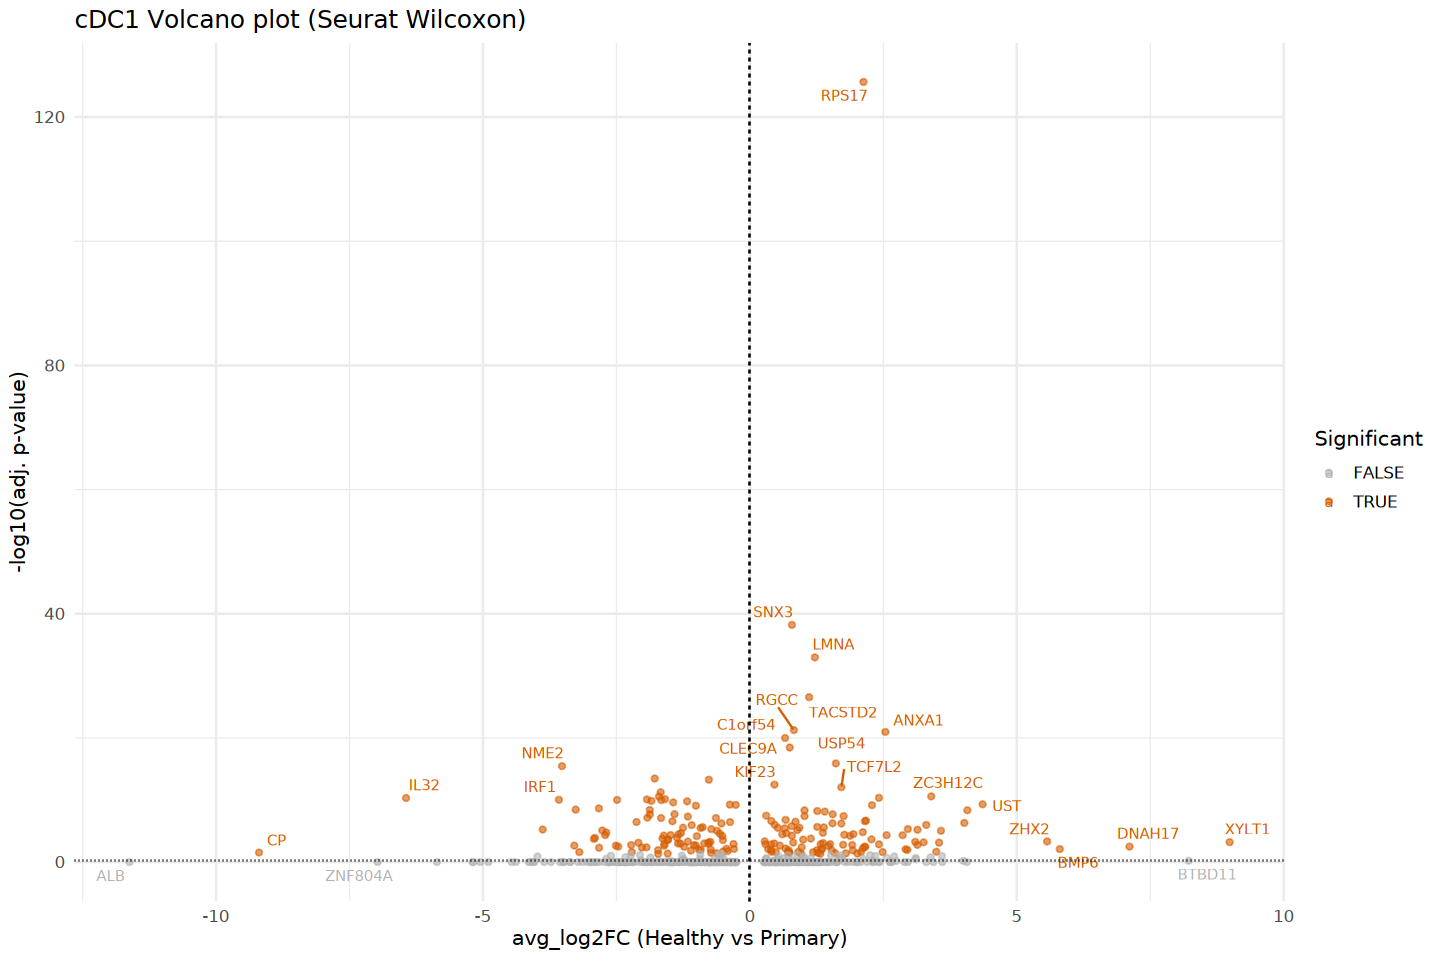

In [63]:

ggplot(dc1_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "cDC1 Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Primary)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


Create Violin plot - cDC2

In [68]:
dc2_vp <- deg_res_dc2%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

head(dc2_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,RPS17,1.567235e-229,1.520536,0.840,0.531,2.736392e-226,225.56282,TRUE
2,IFITM3,1.478491e-106,-2.880824,0.393,0.606,2.581446e-103,102.58814,TRUE
3,IFITM2,3.086161e-65,-2.327153,0.371,0.543,5.388438e-62,61.26854,TRUE
4,SPP1,3.305750e-65,-6.664380,0.031,0.202,5.771839e-62,61.23869,TRUE
5,IFI6,4.218011e-58,-1.837905,0.235,0.385,7.364647e-55,54.13285,TRUE
6,LMNA,8.156201e-57,1.097379,0.626,0.467,1.424073e-53,52.84647,TRUE


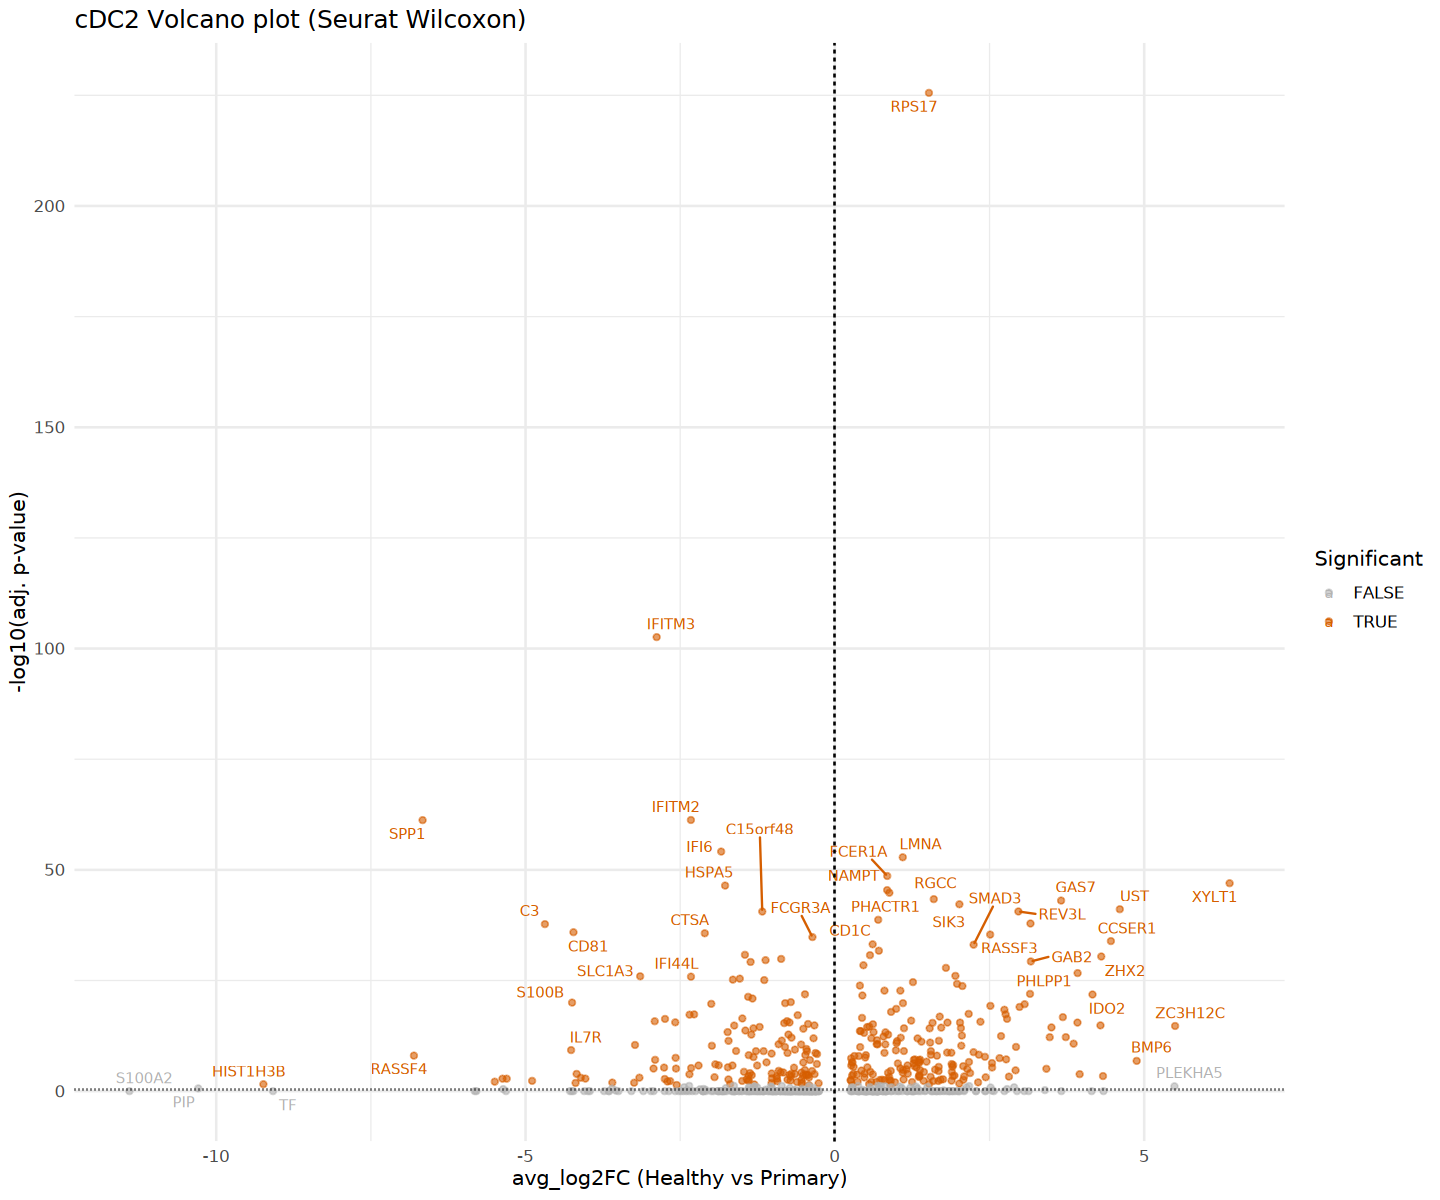

: 

In [ ]:

ggplot(dc2_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "cDC2 Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Primary)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


# Dot Plot

In [67]:
options(repr.plot.width= 20, repr.plot.height= 5)

In [76]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 20))
top_genes_dc1

[1] "RHOB"    "SLC34A2" "CSF1"    "CEACAM6" "CD9"     "KSR1"    "TWISTNB"
 [8] "AHRR"    "MT1X"    "RASA2"   "STARD13" "SDC1"    "FOXO3"   "A2M"    
[15] "LPCAT1"  "GPX3"    "EPB41L3" "CYB5A"   "FRMD4A"  "BHLHE41"

Warning message:
“Scaling data with a low number of groups may produce misleading results”


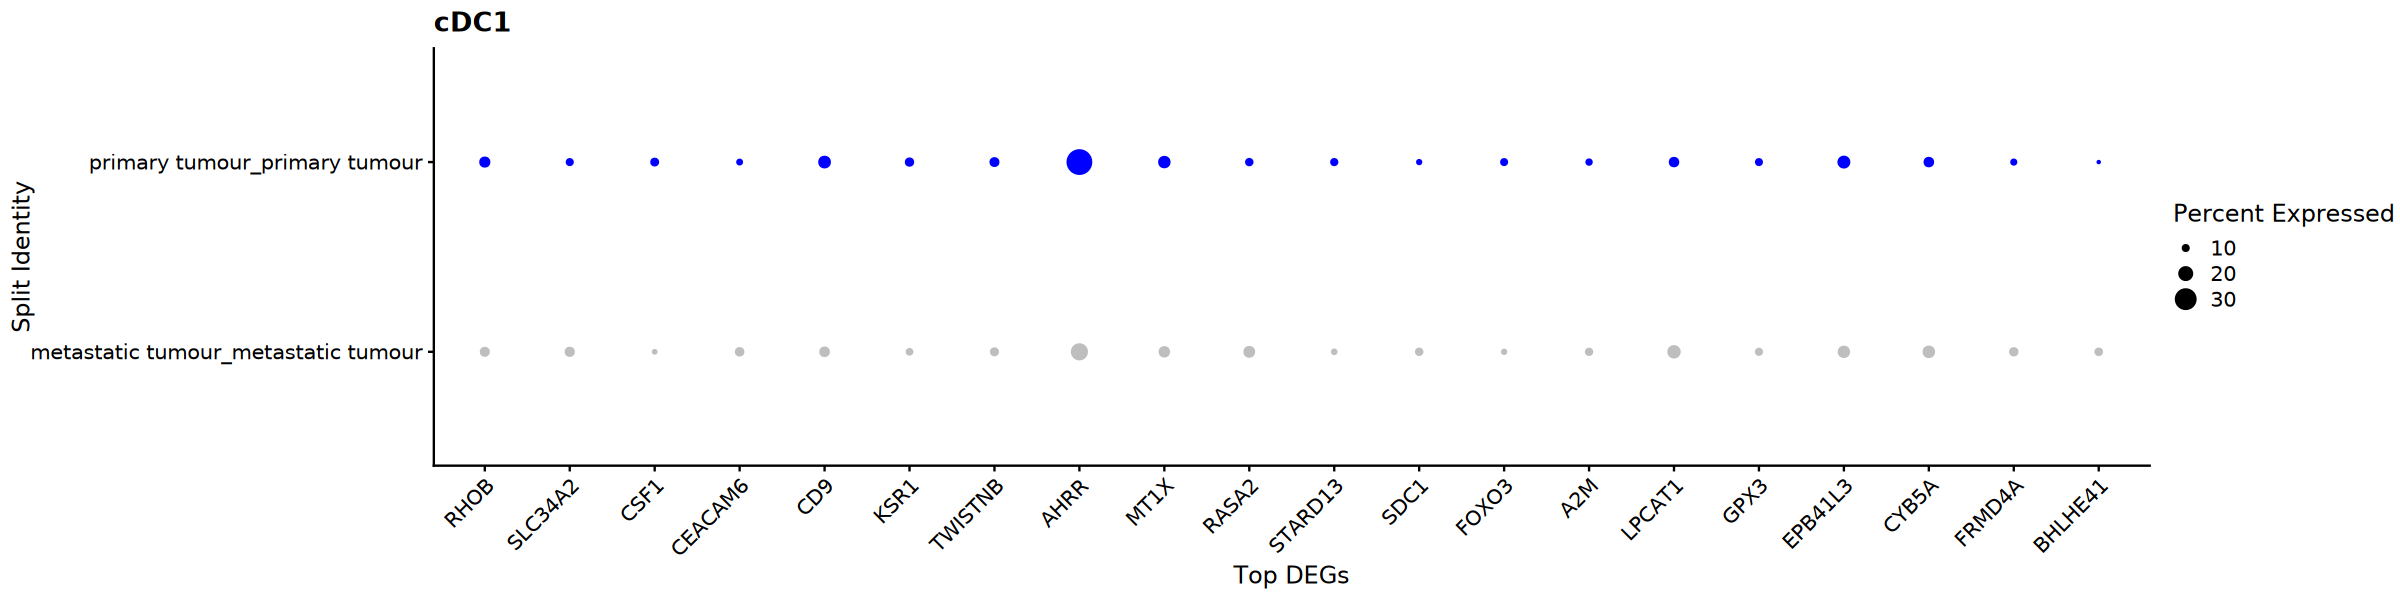

In [77]:
# SplitDotPlotGG has been replaced with the `split.by` parameter for DotPlot
p <- DotPlot(data_cDC1_sub, features = top_genes_dc1[1:20], split.by = "sample_type_major2") + RotatedAxis()
p + labs(title = "cDC1", x = "Top DEGs")

In [ ]:
DotPlot(data_cDC1_sub, features = deg_res_dc1, split.by = "sample_type_major2") + RotatedAxis()

Warning message:
“The following requested variables were not found (10 out of 1758 shown): 1.23541208033858e-129, 3.52208475873295e-42, 6.13425326745766e-37, 1.61883331563508e-30, 3.1692750550465e-25, 6.14236922504983e-25, 5.97745306919556e-24, 2.02095698740908e-22, 7.36547110598023e-20, 2.05786056489954e-19”
Warning message:
“Removing 4246 cells missing data for vars requested”


ERROR: Error in `$<-.data.frame`(`*tmp*`, "id", value = structure(c(`GSE154826_D1_AACCGCGAGAAGGGTA-1` = 1L, : replacement has 4246 rows, data has 0


: 